# CEC

> Transfer of a CNN for cation exchange capacity (CEC) from OSSL to Fukushima: zero-shot, head-only, fine-tuned and Fukushima-only models

In [ ]:
import numpy as np, pandas as pd
from fastcore.test import *
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import *

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`. The outputs come from a local run on an Apple silicon GPU (MPS). `02_transfer` defines the functions used here.

## Data

OSSL MIR spectra on the shared grid, with CEC in cmolc/kg. The models predict `log1p(CEC)`:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo, _ = om.xy('cec_usda.a723_cmolc.kg')
yo = np.log1p(yo.ravel())
Xo.shape

(57062, 1675)

The Fukushima spectra, with CEC in meq/100 g, which equals cmolc/kg. The test set is the Cs137 study's test set:

In [ ]:
#| fukudata
fuku = load_fuku()
fuku.source = fuku.source.assign(target=fuku.source['soil_CEC'])
Xf, yf, idf = fuku.xy('target')
yf = np.log1p(yf.ravel())
_, test_ids = cs137_split()
is_test = np.isin(idf, test_ids)
yt = yf[is_test]
Xf.shape, int(is_test.sum())

((1386, 1675), 340)

## Pretraining

Each preprocessing is fitted on OSSL and applied to Fukushima. `pretrain` trains on OSSL, or loads the weights of an earlier run. The table shows the last epoch of each pretraining, with the R² of the OSSL validation set:

In [ ]:
#| fukudata
X = {k: (p.fit_transform(Xo), p.transform(Xf)) for k, p in preprocessings().items()}
pretrained = {k: pretrain(Xo_k, yo, f'ossl_cec_{k}') for k, (Xo_k, _) in X.items()}
pd.DataFrame({k: pretrain_history(f'ossl_cec_{k}').iloc[-1] for k in X}).T.round(3)

,train_loss,valid_loss,r2_score
snv,0.042,0.031,0.962
snv_d1,0.037,0.028,0.966


## Comparison

Each Fukushima model trains with five seeds. The table gives the mean and standard deviation over the seeds of R² and correlation `r` of `log1p(CEC)`, and of the RMSE and bias of CEC in cmolc/kg, on the test samples:

In [ ]:
#| fukudata
res, preds = compare(pretrained, {k: Xf_k for k, (_, Xf_k) in X.items()}, yf, is_test)
summarise(res).round(3)

R²             r  ...          bias       
                               mean    std   mean  ...    std   mean    std
preprocessing model                                ...                     
snv           zero-shot      -3.831  0.000  0.477  ...  0.000 -7.670  0.000
              head only       0.292  0.008  0.591  ...  0.025 -0.871  0.060
              fine-tuned      0.337  0.004  0.614  ...  0.017 -0.383  0.079
              Fukushima only  0.484  0.017  0.710  ...  0.080 -0.787  0.181
snv_d1        zero-shot      -0.695  0.000  0.572  ...  0.000 -2.994  0.000
              head only       0.314  0.003  0.610  ...  0.015 -0.293  0.077
              fine-tuned      0.388  0.002  0.647  ...  0.007 -0.260  0.060
              Fukushima only  0.590  0.006  0.778  ...  0.018 -0.900  0.188

[8 rows x 8 columns]

For scale, the standard deviation of the test CEC values, in cmolc/kg:

In [ ]:
#| fukudata
round(float(np.expm1(yt).std()), 3)

5.612

Predictions of the first seed against the observed values:

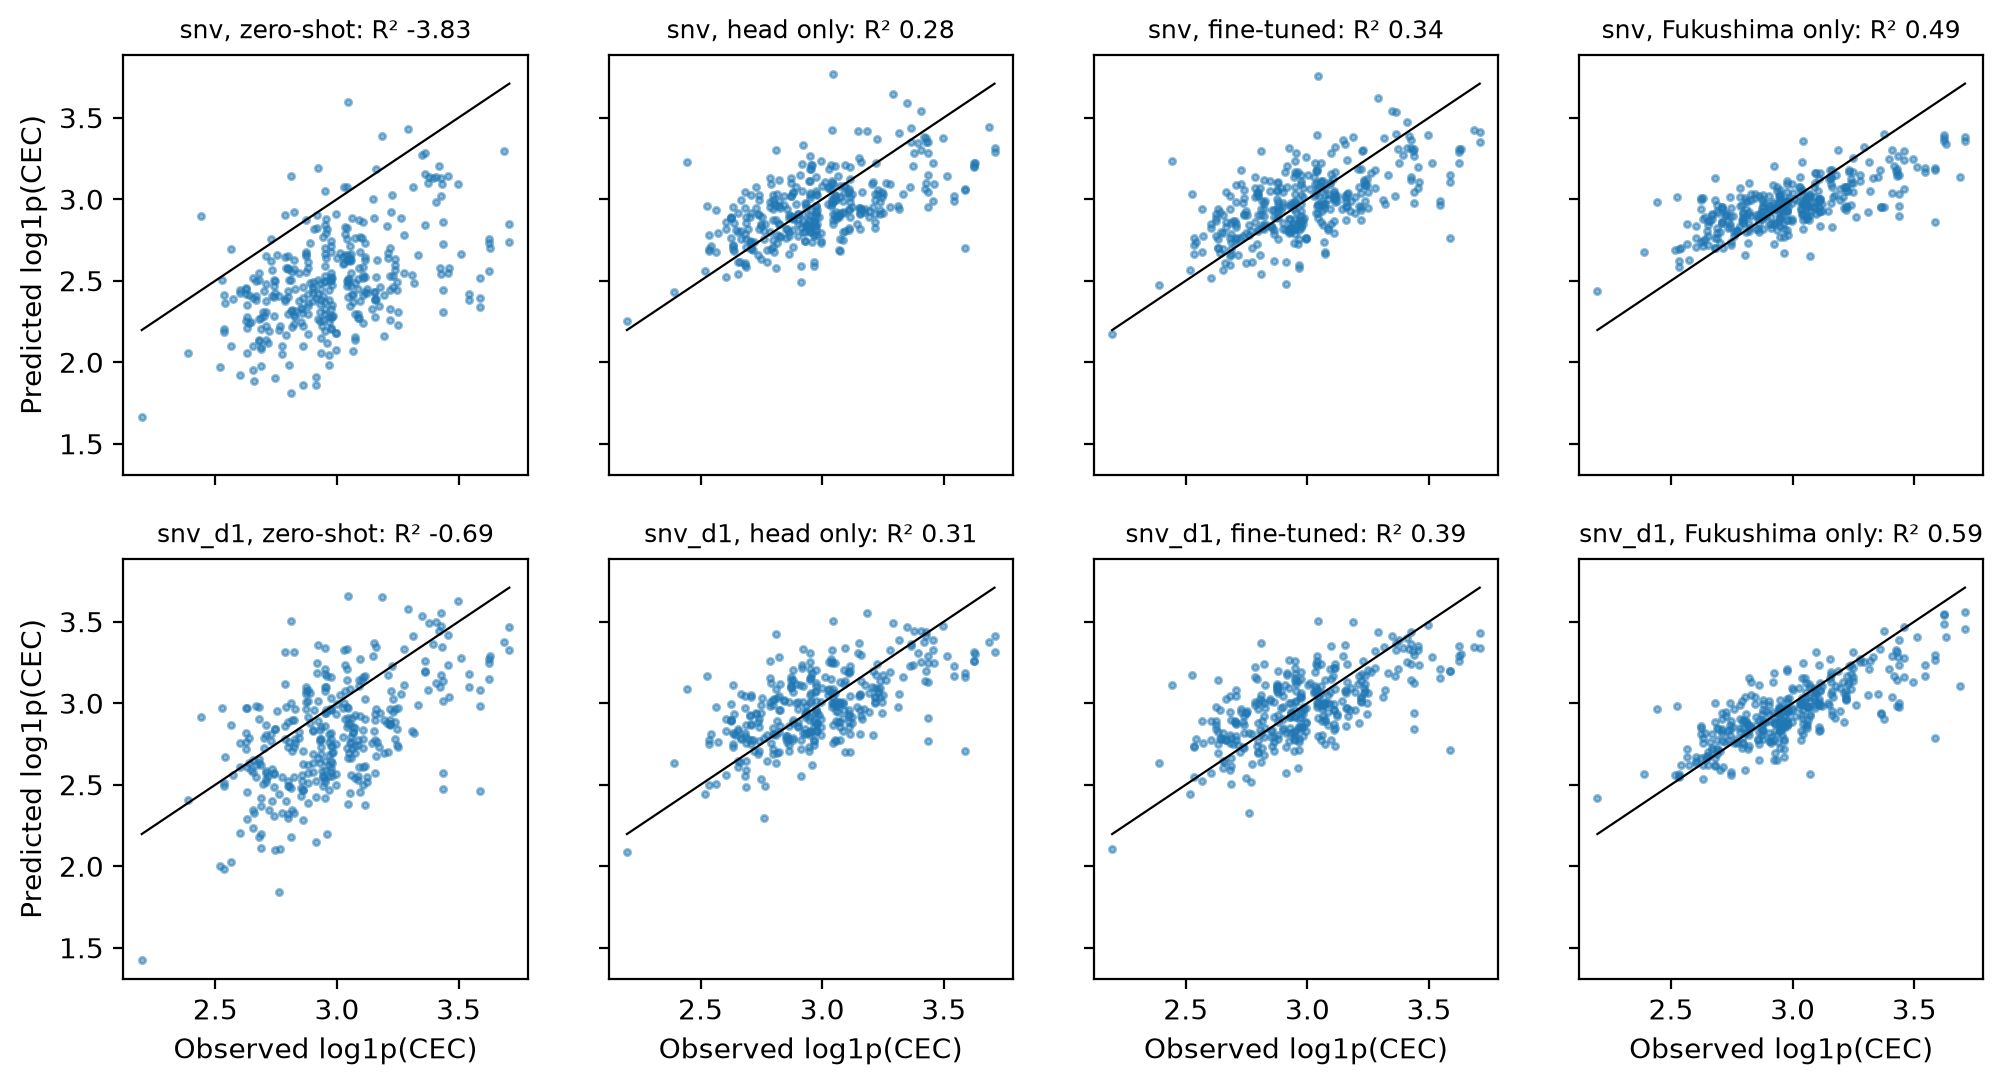

In [ ]:
#| fukudata
plot_preds(preds, yt, label='log1p(CEC)');

## Checks

The OSSL validation R² covers OSSL's whole CEC range. The pretrained models are scored again on their OSSL validation samples, first all of them, then those within the 5th to 95th percentile of Fukushima CEC:

In [ ]:
#| fukudata
lo, hi = np.quantile(yf, [0.05, 0.95])
np.expm1([lo, hi]).round(2), pd.DataFrame({k: range_check(Xo_k, yo, pretrained[k], lo, hi) for k, (Xo_k, _) in X.items()}).T.round(3)

(array([11.2 , 30.77]),
          n all  R² all  r all  n in range  R² in range  r in range
 snv     5706.0   0.962  0.981      2677.0        0.621       0.841
 snv_d1  5706.0   0.966  0.983      2677.0        0.660       0.857)

## Error analysis

Mean absolute error of `log1p(CEC)` with the derivative preprocessing, by soil type, year and measurement batch. Each model's predictions are averaged over the seeds first:

In [ ]:
#| fukudata
props = fuku.source.loc[idf[is_test]]
error_table(preds, yt, props['Soil_type_describe'], 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
Andosols,0.161,0.153,0.167,44
Forest soil,0.204,0.194,0.098,27
Glay soil,0.171,0.160,0.069,6
Lowland soil,0.169,0.158,0.116,243
Peat soil,0.150,0.133,0.130,14
Red yellow soil,0.129,0.118,0.078,6


In [ ]:
#| fukudata
error_table(preds, yt, props['year'].astype(int), 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
2013,0.205,0.195,0.140,34
2014,0.162,0.138,0.108,53
2015,0.143,0.137,0.112,48
2016,0.154,0.147,0.098,58
2017,0.181,0.167,0.132,37
2018,0.217,0.204,0.138,46
2019,0.136,0.132,0.120,48
2020,0.184,0.174,0.145,16


In [ ]:
#| fukudata
error_table(preds, yt, sample_batches(idf[is_test]), 'snv_d1').round(3)

,head only,fine-tuned,Fukushima only,n
batch 1,0.193,0.176,0.125,110
batch 2,0.158,0.150,0.118,230


## Findings

The pretrained models come from one pretraining run each. The Fukushima-side training was repeated with five seeds, and the standard deviations over the seeds are small, at most 0.02 in R². Training on MPS is not fully deterministic, and the variation between pretraining runs is not measured.

Pretraining works well. The OSSL validation R² of `log1p(CEC)` is 0.96 with SNV and 0.97 with the derivative. On OSSL validation samples within Fukushima's CEC range (11.2 to 30.8 cmolc/kg), the correlation stays at 0.84 and 0.86.

Unlike for Kex, the OSSL models partly rank the Fukushima samples without training: their correlation is 0.48 with SNV and 0.57 with the derivative. They predict much too low. The bias is -7.7 cmolc/kg with SNV and -3.0 with the derivative, against a median Fukushima CEC of 18 cmolc/kg. The zero-shot R² is therefore negative.

The CNN trained on Fukushima samples only is again the best model: R² 0.59, correlation 0.78 and RMSE 3.7 cmolc/kg with the derivative, against a standard deviation of 5.6 cmolc/kg for the test values. A linear head on the frozen OSSL backbone gives R² 0.31, and fine-tuning 0.39. The fine-tuned backbone trains at a maximum learning rate of 5e-6 (see `02_transfer`), so it stays close to the OSSL weights. The frozen OSSL features carry less information about Fukushima CEC than the features the Fukushima-only model learns. Whether full fine-tuning, with the backbone free to change, does better is not tested yet.

The derivative improves every Fukushima model. The Fukushima-only model has the lowest error in almost every soil type, year and batch. The gap is largest for forest soils (mean absolute error of `log1p(CEC)` 0.10 against 0.19 to 0.20), but that group has 27 test samples.